In [12]:
from google.colab import drive
import os, shutil

drive.mount('/content/drive')          # click through the authorisation popup
SRC = "/content/drive/MyDrive/ML Mini Project"

for f in ["tracks.csv", "artists.csv"]:
    shutil.copy(os.path.join(SRC, f), "/content/" + f)
    print(f, round(os.path.getsize("/content/" + f) / 1e6, 1), "MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
tracks.csv 111.4 MB
artists.csv 64.9 MB


# Reproduce & Extend: *Training a Playlist Curator Based on User Taste*

**Reference:** Awadelkarim & Coelho (Stanford, 2018) — poster + paper, with the authors' code at
[`kevin-coelho/playlistr-ml-v1`](https://github.com/kevin-coelho/playlistr-ml-v1) (data collection) and
[`kevin-coelho/playlistr-ml-py-v1`](https://github.com/kevin-coelho/playlistr-ml-py-v1) (algorithms).
**Task:** classify songs into the playlist they belong to, using Spotify audio features + genre tags.

This notebook follows the *Mini Project Guidelines: Reproduce and Extend*.

| Part | What | Where |
|---|---|---|
| **Part 1** | Reproduce the reported pipeline: Perceptron, Polynomial/Sigmoid/RBF SVMs (scaled vs unscaled, 5-fold CV), tuned RBF SVM + per-class report, 1- and 2-hidden-layer neural networks (PyTorch) | Sections 3–6 |
| **Part 2** | One additional model not in the reference: **XGBoost** (gradient-boosted decision trees) on the *same* data, split and metrics | Section 8 |
| **Comparison** | *Reported vs. Your Result* table, extended comparison, discussion | Sections 7, 9, 10 |

### Which data does this notebook use?
The authors published the **exact 13 Spotify-curated playlists and their tracks** (Spotify track IDs, names, artists, artist IDs) in their JavaScript repo (`get_toy_set/results/toy_data_set_playlists_full.json`, 1,027 track entries, snapshot from Dec 2018). Their **audio features and genre tags lived in a private Postgres database that was never published**, and Spotify's `audio-features` endpoint has been closed to new apps since Nov 2024. So the notebook rebuilds the dataset in two steps:

1. **`DATA_SOURCE = "paper"` (default): the authors' exact playlists and tracks**, then re-attach the 10 audio features and the genre tags from the best available source (Section 1b):
   * audio features: your own Kaggle CSV matched by Spotify track ID (*exact Spotify values*), and/or the free ReccoBeats API by Spotify track ID (*estimates that mirror Spotify's features, not the original numbers*);
   * genre tags: Spotify's artist genres (Spotify API with your own free client credentials) or a Kaggle artist-genre CSV; if neither is available, the notebook falls back to a multi-hot **artist** vector (and tells you).
2. **`DATA_SOURCE = "proxy"` (fallback):** 13 proxy playlists built from the public *Spotify Tracks Dataset* genres (no downloads of the authors' files needed).

Either way, the coverage of the rebuilt data is reported explicitly (how many of the 1,027 tracks got features/tags), and every deviation from the paper is something you should state in your report. The authors' real-user data (Table 4) is private (only friends' playlist *names* are in the repo), so Section 6 uses a clearly-labelled **proxy**.

In [13]:
# ---- Setup ---------------------------------------------------------------
import os, sys, re, ast, random, warnings, subprocess, importlib, json, time, unicodedata
from collections import Counter

def _ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for p, n in [("xgboost", None), ("torch", None), ("scikit-learn", "sklearn"), ("requests", None)]:
    _ensure(p, n)

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import xgboost as xgb
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import Perceptron
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

# ================= CONFIG (edit here) =======================================
DATA_SOURCE = os.environ.get("DATA_SOURCE", "paper")      # "paper" = authors' exact playlists/tracks, "proxy" = public-genre proxy playlists

# --- DATA_SOURCE = "paper": where to get the missing audio features and genre tags
PAPER_JSON_PATH = os.environ.get("PAPER_JSON", "")        # optional local copy of toy_data_set_playlists_full.json
PAPER_JSON_URL = ("https://raw.githubusercontent.com/kevin-coelho/playlistr-ml-v1/master/"
                  "get_toy_set/results/toy_data_set_playlists_full.json")
FEATURE_CSV_PATHS = ["/content/tracks.csv"]   # Kaggle CSV(s) with a Spotify track-id column + audio features
USE_RECCOBEATS = True       # fill still-missing audio features from the free ReccoBeats API (estimates, not Spotify's original numbers)
ONLY_EXACT_FEATURES = False # True = keep only tracks whose features come from your CSVs (exact Spotify values, smaller dataset)
GENRE_CSV_PATH = "/content/artists.csv"         # Kaggle artist-genre CSV (artists.csv with id+genres, or data_w_genres.csv with artists+genres)
SPOTIFY_CLIENT_ID = os.environ.get("SPOTIFY_CLIENT_ID", "")      # optional: free dev app, used only to read artist genres
SPOTIFY_CLIENT_SECRET = os.environ.get("SPOTIFY_CLIENT_SECRET", "")
MIN_TRACKS_PER_PLAYLIST = 12  # stop early if a playlist ends up with fewer rematched tracks than this

# --- DATA_SOURCE = "proxy" (public Spotify Tracks Dataset, one genre per proxy playlist)
DATA_PATH = os.environ.get("SPOTIFY_CSV", "")              # optional local copy of the Spotify Tracks Dataset dataset.csv
N_TAGS = 2095               # size of the tag block in proxy mode (paper: 2095 genre tags)
TOTAL_TRACKS = 1044         # proxy mode: paper's toy-set size

# --- common
TEST_SIZE = 0.20            # paper: 80/20 split
CV_FOLDS = 5                # paper: k = 5
NN_EPOCHS = 150             # paper: 150 epochs
NN_SEEDS = 5                # NN is stochastic (init) -> average over seeds
RUN_PROXY_USERS = True      # Section 6 (proxy for the paper's private user data; needs the public Spotify Tracks Dataset)
OUT_DIR = "results"; os.makedirs(OUT_DIR, exist_ok=True)
assert DATA_SOURCE in ("paper", "proxy")
print("torch", torch.__version__, "| xgboost", xgb.__version__, "| DATA_SOURCE =", DATA_SOURCE)

AUDIO = ["danceability","energy","key","loudness","mode","speechiness",
         "acousticness","liveness","valence","tempo"]    # the paper's 10 audio features
PLAYLISTS = ["Swagger","Spread the Gospel","'90s Baby Makers","Tender","Have a Great Day!","Dance Rising",
             "Sad Vibe","Afternoon Acoustic","Kitchen Swagger","All The Feels","Jazz Vibes","Celtic Punk",
             "Country by the Grace of God"]               # the paper's 13 playlists (Table 2 order)
PAPER_SUPPORT = {"Swagger":76,"Spread the Gospel":40,"'90s Baby Makers":47,"Tender":33,
    "Have a Great Day!":100,"Dance Rising":99,"Sad Vibe":42,"Afternoon Acoustic":76,
    "Kitchen Swagger":75,"All The Feels":65,"Jazz Vibes":118,"Celtic Punk":49,
    "Country by the Grace of God":49}                     # paper Table 2 'support' column

torch 2.11.0+cpu | xgboost 3.4.1 | DATA_SOURCE = paper


## 1. Data
### 1a. The authors' exact playlists and tracks (`DATA_SOURCE = "paper"`)
Downloaded straight from the authors' GitHub repo (or from `PAPER_JSON_PATH`). This gives, per playlist, every track's Spotify ID, name, artists and artist IDs. *No audio features or genres are in this file* — Section 1b re-attaches them.

In [14]:
def load_paper_json():
    if PAPER_JSON_PATH and os.path.exists(PAPER_JSON_PATH):
        return json.load(open(PAPER_JSON_PATH, encoding="utf-8"))
    r = requests.get(PAPER_JSON_URL, timeout=60); r.raise_for_status()
    return r.json()

def paper_track_table(playlists_json):
    rows = []
    for p in playlists_json:
        items = p["tracks"] if isinstance(p["tracks"], list) else p["tracks"].get("items", [])
        for it in items:
            t = it.get("track")
            if not t or not t.get("id"): continue
            rows.append(dict(track_id=t["id"], name=t["name"], isrc=(t.get("external_ids") or {}).get("isrc"),
                             artists=";".join(a["name"] for a in t["artists"]),
                             artist_ids=";".join(a["id"] for a in t["artists"]), playlist=p["name"]))
    return pd.DataFrame(rows)

if DATA_SOURCE == "paper":
    paper_raw = paper_track_table(load_paper_json())
    # a track listed in two playlists is ambiguous for single-label classification -> drop it
    dup = paper_raw.track_id[paper_raw.track_id.duplicated(keep=False)].unique()
    paper_tracks = paper_raw[~paper_raw.track_id.isin(dup)].reset_index(drop=True)
    print(f"{len(paper_raw)} track entries in the authors' 13 playlists; dropped {len(dup)} track(s) listed in >1 playlist "
          f"-> {len(paper_tracks)} tracks, {paper_tracks.artist_ids.str.split(';').explode().nunique()} distinct artists")
    missing_pl = set(PLAYLISTS) - set(paper_tracks.playlist)
    assert not missing_pl, f"playlists missing from JSON: {missing_pl}"
    display(paper_tracks.groupby("playlist").size().reindex(PLAYLISTS).rename("tracks in authors' JSON").to_frame()
            .assign(**{"paper Table 2 support": pd.Series(PAPER_SUPPORT)}).T)

1027 track entries in the authors' 13 playlists; dropped 1 track(s) listed in >1 playlist -> 1025 tracks, 953 distinct artists


playlist,Swagger,Spread the Gospel,'90s Baby Makers,Tender,Have a Great Day!,Dance Rising,Sad Vibe,Afternoon Acoustic,Kitchen Swagger,All The Feels,Jazz Vibes,Celtic Punk,Country by the Grace of God
tracks in authors' JSON,96,50,48,50,101,95,55,86,77,64,200,50,53
paper Table 2 support,76,40,47,33,100,99,42,76,75,65,118,49,49


### 1b. Re-attach the audio features and genre tags (`DATA_SOURCE = "paper"`)
**Audio features** (the paper's 10), in priority order, recording where each track's values came from:
1. `FEATURE_CSV_PATHS`: your own Kaggle CSV(s), matched on the Spotify track ID (exact Spotify values), then on normalised *title + first artist* for tracks not matched by ID. Good sources with Spotify IDs: *Spotify Dataset 1921–2020* (`tracks.csv` / `data.csv`), *Ultimate Spotify Tracks DB*, *30000 Spotify Songs*.
2. ReccoBeats API (`USE_RECCOBEATS`): free, no key, accepts Spotify track IDs, but its values are estimates, so the notebook records them separately and you must state this in the report.

**Genre tags** (paper: Spotify's artist genres, multi-hot, summed over the track's artists):
1. Spotify Web API artist genres, if you set `SPOTIFY_CLIENT_ID`/`SECRET` (free dev app, client-credentials flow). This is the paper's own source.
2. else a Kaggle artist-genre CSV (`GENRE_CSV_PATH`): `artists.csv` (columns `id`, `genres`) or `data_w_genres.csv` (`artists`, `genres`).
3. else a multi-hot of the **artists** themselves (fallback; stated in the output).

All downloads are cached in `results/` so re-runs don't hit the APIs again.

In [15]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"\(.*?\)|\[.*?\]", "", s); s = re.sub(r"\s-\s.*$", "", s)
    s = re.sub(r"[^a-z0-9 ]", "", s); return re.sub(r"\s+", " ", s).strip()

def first_artist(s):
    s = str(s)
    if s.startswith("["):                       # e.g. "['Artist A', 'Artist B']"
        try: s = ast.literal_eval(s)[0]
        except Exception: pass
    return str(s).split(";")[0]

def read_feature_csvs(paths):
    # returns a table with track_id (may be NaN), key (title|artist) and the AUDIO columns
    frames = []
    for p in paths:
        df = pd.read_csv(p)
        df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
        idcol = next((c for c in ("id", "track_id", "spotify_id") if c in df.columns), None)
        namecol = next((c for c in ("name", "track_name", "song", "title") if c in df.columns), None)
        artcol = next((c for c in ("artists", "track_artist", "artist", "artist_name") if c in df.columns), None)
        miss = [c for c in AUDIO if c not in df.columns]
        if miss: print(f"  skipping {p}: missing columns {miss}"); continue
        out = df[AUDIO].copy()
        out["track_id"] = df[idcol] if idcol else np.nan
        out["key_na"] = (df[namecol].map(norm) + "|" + df[artcol].map(first_artist).map(norm)) if namecol and artcol else np.nan
        frames.append(out)
        print(f"  loaded {p}: {len(df):,} rows (id column: {idcol}, name/artist match: {bool(namecol and artcol)})")
    if not frames: return None
    return pd.concat(frames, ignore_index=True)

def reccobeats_features(ids, cache="results/reccobeats_cache.csv"):
    # ReccoBeats: GET /v1/audio-features?ids=<spotify ids, <=40 per call>; the Spotify id is recovered from each record's href.
    have = pd.read_csv(cache) if os.path.exists(cache) else pd.DataFrame(columns=["track_id"] + AUDIO)
    todo = [i for i in ids if i not in set(have.track_id)]
    recs, shown, failures = [], False, 0
    for k in range(0, len(todo), 40):
        chunk = todo[k:k+40]
        for attempt in range(4):
            try:
                r = requests.get("https://api.reccobeats.com/v1/audio-features", params={"ids": ",".join(chunk)}, timeout=40)
            except Exception as e:
                r = None; time.sleep(2); continue
            if r.status_code == 429: time.sleep(5 * (attempt + 1)); continue
            break
        if r is None or r.status_code != 200:
            failures += 1
            print("  ReccoBeats batch failed:", "no connection" if r is None else f"HTTP {r.status_code} {r.text[:120]}")
            if failures >= 3: print("  giving up on ReccoBeats after 3 failed batches"); break
            continue
        content = (r.json() or {}).get("content", [])
        for rec in content:
            m = re.search(r"track/([A-Za-z0-9]{22})", str(rec.get("href", "")))
            if not m and not shown:
                print("  note: could not read a Spotify id from this record, keys =", list(rec)[:14]); shown = True
            if m and all(a in rec for a in AUDIO): recs.append({"track_id": m.group(1), **{a: rec[a] for a in AUDIO}})
        time.sleep(0.3)
    new = pd.DataFrame(recs, columns=["track_id"] + AUDIO)
    allr = pd.concat([have, new], ignore_index=True).drop_duplicates("track_id")
    if len(allr): allr.to_csv(cache, index=False)
    return allr[allr.track_id.isin(ids)]

def attach_audio(tracks):
    t = tracks.copy(); t["feat_source"] = pd.Series([None] * len(t), dtype="object", index=t.index)
    for a in AUDIO: t[a] = np.nan
    t["key_na"] = t.name.map(norm) + "|" + t.artists.map(first_artist).map(norm)
    src = read_feature_csvs(FEATURE_CSV_PATHS) if FEATURE_CSV_PATHS else None
    if src is not None:
        by_id = src.dropna(subset=["track_id"]).drop_duplicates("track_id").set_index("track_id")[AUDIO]
        m = t.track_id.isin(by_id.index)
        t.loc[m, AUDIO] = by_id.loc[t.track_id[m], AUDIO].to_numpy(); t.loc[m, "feat_source"] = "csv (track id)"
        by_key = src.dropna(subset=["key_na"]).drop_duplicates("key_na").set_index("key_na")[AUDIO]
        m2 = t.feat_source.isna() & t.key_na.isin(by_key.index)
        t.loc[m2, AUDIO] = by_key.loc[t.key_na[m2], AUDIO].to_numpy(); t.loc[m2, "feat_source"] = "csv (title+artist)"
    if USE_RECCOBEATS and not ONLY_EXACT_FEATURES:
        need = t.track_id[t.feat_source.isna()].tolist()
        if need:
            print(f"  asking ReccoBeats for {len(need)} tracks ...")
            rb = reccobeats_features(need).drop_duplicates("track_id").set_index("track_id")
            m3 = t.feat_source.isna() & t.track_id.isin(rb.index)
            if m3.any():
                t.loc[m3, AUDIO] = rb.loc[t.track_id[m3], AUDIO].to_numpy(); t.loc[m3, "feat_source"] = "ReccoBeats (estimate)"
    t[AUDIO] = t[AUDIO].astype(float)
    return t

def parse_genres(x):
    if isinstance(x, list): return x
    if x is None or (isinstance(x, float) and np.isnan(x)): return []
    x = str(x).strip()
    if x.startswith("["):
        try: return [g.strip() for g in ast.literal_eval(x)]
        except Exception: pass
    return [g.strip() for g in re.split(r"[;,]", x.strip("[]")) if g.strip()]

def spotify_artist_genres(artist_ids, cache="results/artist_genres_spotify.json"):
    cached = json.load(open(cache)) if os.path.exists(cache) else {}
    todo = [a for a in artist_ids if a not in cached]
    if todo and SPOTIFY_CLIENT_ID and SPOTIFY_CLIENT_SECRET:
        tok = requests.post("https://accounts.spotify.com/api/token", data={"grant_type": "client_credentials"},
                            auth=(SPOTIFY_CLIENT_ID, SPOTIFY_CLIENT_SECRET), timeout=30)
        if tok.status_code != 200: print("  Spotify token request failed:", tok.status_code, tok.text[:120]); return cached
        h = {"Authorization": "Bearer " + tok.json()["access_token"]}
        for k in range(0, len(todo), 50):
            r = requests.get("https://api.spotify.com/v1/artists", params={"ids": ",".join(todo[k:k+50])}, headers=h, timeout=30)
            if r.status_code != 200: print("  Spotify artists HTTP", r.status_code, r.text[:120]); break
            for a in r.json().get("artists", []):
                if a: cached[a["id"]] = a.get("genres", [])
        json.dump(cached, open(cache, "w"))
    return cached

def attach_genres(t):
    aid_lists = t.artist_ids.str.split(";")
    all_aids = sorted({a for l in aid_lists for a in l})
    ag, how = {}, None
    sp = spotify_artist_genres(all_aids)
    if sp and sum(1 for a in all_aids if sp.get(a)) > 0.3 * len(all_aids):
        ag, how = sp, "Spotify Web API artist genres"
    elif GENRE_CSV_PATH and os.path.exists(GENRE_CSV_PATH):
        g = pd.read_csv(GENRE_CSV_PATH)
        if "id" in g.columns and "genres" in g.columns:
            ag = {r.id: parse_genres(r.genres) for r in g.itertuples()}; how = "Kaggle artist-genre CSV (by artist id)"
        elif "artists" in g.columns and "genres" in g.columns:
            by_name = {norm(r.artists): parse_genres(r.genres) for r in g.itertuples()}
            names = {a: n for l, nl in zip(aid_lists, t.artists.str.split(";")) for a, n in zip(l, nl)}
            ag = {a: by_name.get(norm(n), []) for a, n in names.items()}; how = "Kaggle artist-genre CSV (by artist name)"
    if how and sum(1 for a in all_aids if ag.get(a)) < 0.3 * len(all_aids):
        print("  genre source found but covers <30% of artists, ignoring it"); how = None
    if how:
        t = t.copy(); t["genres"] = [sorted({gg for a in l for gg in ag.get(a, [])}) for l in aid_lists]
        return t, how
    return t, None

if DATA_SOURCE == "paper":
    t0 = attach_audio(paper_tracks)
    print("audio-feature sources:", t0.feat_source.fillna("MISSING").value_counts().to_dict())
    cov = (t0.assign(has=t0.feat_source.notna()).groupby("playlist").agg(tracks=("has", "size"), with_features=("has", "sum")))
    display(cov.reindex(PLAYLISTS).T)
    if ONLY_EXACT_FEATURES: t0 = t0[t0.feat_source.str.startswith("csv", na=False)]
    t0 = t0[t0.feat_source.notna()].reset_index(drop=True)
    if len(t0) < 0.5 * len(paper_tracks):
        print("\nWARNING: only %d of %d tracks have audio features. Add Kaggle CSVs to FEATURE_CSV_PATHS and/or check the "
              "ReccoBeats lines above. Results on such a reduced set will differ from the paper." % (len(t0), len(paper_tracks)))
    small = t0.playlist.value_counts().reindex(PLAYLISTS).fillna(0)
    assert (small >= MIN_TRACKS_PER_PLAYLIST).all(), ("Too few tracks have features for: " +
        ", ".join(small[small < MIN_TRACKS_PER_PLAYLIST].index) + ". Provide more feature sources (see Section 1b).")
    t1, genre_source = attach_genres(t0)
    print("genre tags source:", genre_source or "none -> falling back to artist multi-hot")

  loaded /content/tracks.csv: 586,672 rows (id column: id, name/artist match: True)
  asking ReccoBeats for 645 tracks ...
audio-feature sources: {'MISSING': 347, 'ReccoBeats (estimate)': 298, 'csv (track id)': 248, 'csv (title+artist)': 132}


playlist,Swagger,Spread the Gospel,'90s Baby Makers,Tender,Have a Great Day!,Dance Rising,Sad Vibe,Afternoon Acoustic,Kitchen Swagger,All The Feels,Jazz Vibes,Celtic Punk,Country by the Grace of God
tracks,96,50,48,50,101,95,55,86,77,64,200,50,53
with_features,52,33,48,21,101,62,20,52,65,61,83,35,45


genre tags source: Kaggle artist-genre CSV (by artist id)


### 1c. Feature matrix (`DATA_SOURCE = "paper"`)
`x = [10 audio features | multi-hot genre tags]`, the paper's layout. With Spotify genres the tag block has one column per distinct genre present in the playlists (the paper's 2,095 was the size of its full genre table, so our width is smaller, but the encoding is the same).

In [16]:
def build_paper_matrix(t, genre_source):
    if genre_source:
        vocab_ = sorted({g for gl in t.genres for g in gl})
        gi = {g: i for i, g in enumerate(vocab_)}
        T = np.zeros((len(t), len(vocab_)), np.float32)
        for r, gl in enumerate(t.genres):
            for g in gl: T[r, gi[g]] = 1.0
        names_ = [f"genre:{g}" for g in vocab_]
    else:                                              # fallback: artists as tags
        cnt = Counter(a for s in t.artists for a in s.split(";"))
        vocab_ = [a for a, _ in cnt.most_common()]; ai = {a: i for i, a in enumerate(vocab_)}
        T = np.zeros((len(t), len(vocab_)), np.float32)
        for r, s in enumerate(t.artists):
            for a in s.split(";"): T[r, ai[a]] = 1.0
        names_ = [f"artist:{a}" for a in vocab_]
    return np.hstack([t[AUDIO].to_numpy(np.float32), T]), names_

if DATA_SOURCE == "paper":
    X_all, TAG_NAMES = build_paper_matrix(t1, genre_source)
    toy = t1
    classes = PLAYLISTS
    y_all = toy.playlist.map({p: i for i, p in enumerate(classes)}).to_numpy()
    TAG_DESC = genre_source or "artist multi-hot (fallback)"

### 1d. Proxy dataset (`DATA_SOURCE = "proxy"`, fallback)
Only used if you switch the config. 13 proxy playlists, one per genre of the public *Spotify Tracks Dataset* (`maharshipandya/spotify-tracks-dataset`), sizes proportional to the paper's Table 2, 1,044 tracks; the 2,095-wide tag block is a multi-hot of the 2,095 most frequent artists (the dataset has a single genre label per track, which would leak the class).

In [17]:
HF_URL = "https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset/resolve/main/dataset.csv"
REQUIRED = ["track_id", "artists", "track_genre"] + AUDIO
PLAYLIST_GENRE = {   # paper playlist -> proxy genre (edit freely)
    "Swagger": "hip-hop", "Spread the Gospel": "gospel", "'90s Baby Makers": "r-n-b", "Tender": "romance",
    "Have a Great Day!": "happy", "Dance Rising": "dance", "Sad Vibe": "sad", "Afternoon Acoustic": "acoustic",
    "Kitchen Swagger": "party", "All The Feels": "singer-songwriter", "Jazz Vibes": "jazz", "Celtic Punk": "punk",
    "Country by the Grace of God": "country"}

def load_spotify():
    tried = []
    if DATA_PATH:
        if os.path.exists(DATA_PATH): return pd.read_csv(DATA_PATH)
        tried.append(f"local file {DATA_PATH} (not found)")
    try: return pd.read_csv(HF_URL)
    except Exception as e: tried.append(f"HF url: {type(e).__name__}")
    try:
        from datasets import load_dataset
        return load_dataset("maharshipandya/spotify-tracks-dataset", split="train").to_pandas()
    except Exception as e: tried.append(f"datasets lib: {type(e).__name__}")
    raise FileNotFoundError("Could not load the Spotify Tracks Dataset. Tried: " + "; ".join(tried) + ". Download dataset.csv and set DATA_PATH.")

raw, avail = None, set()
try:
    raw = load_spotify()
    raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]
    assert not [c for c in REQUIRED if c not in raw.columns]
    raw = raw.dropna(subset=["artists", "track_genre"]).drop_duplicates(subset=["track_id", "track_genre"])
    avail = set(raw.track_genre.unique())
    print("Spotify Tracks Dataset loaded:", raw.shape)
except Exception as e:
    if DATA_SOURCE == "proxy": raise
    print("Public Spotify Tracks Dataset not loaded (only needed for the Section 6 proxy users):", type(e).__name__)

def split_artists(s): return [a.strip() for a in str(s).split(";") if a.strip()]

if DATA_SOURCE == "proxy":
    bad = {p: g for p, g in PLAYLIST_GENRE.items() if g not in avail}
    assert not bad, f"These genres are not in the dataset: {bad}"
    pool = raw[raw.track_genre.isin(PLAYLIST_GENRE.values())].copy()
    dup_ids = pool.track_id[pool.track_id.duplicated(keep=False)].unique()
    pool = pool[~pool.track_id.isin(dup_ids)].drop_duplicates("track_id")
    pool["playlist"] = pool.track_genre.map({g: p for p, g in PLAYLIST_GENRE.items()})
    art_counts = Counter(a for s in pool.artists for a in split_artists(s))
    vocab = [a for a, _ in art_counts.most_common(N_TAGS)]; a2i = {a: i for i, a in enumerate(vocab)}
    tot = sum(PAPER_SUPPORT.values())
    sizes = {p: int(round(PAPER_SUPPORT[p] * TOTAL_TRACKS / tot)) for p in PLAYLISTS}
    sizes[max(sizes, key=sizes.get)] += TOTAL_TRACKS - sum(sizes.values())
    toy = pd.concat([pool[pool.playlist == p].sample(n=min(sizes[p], (pool.playlist == p).sum()), random_state=SEED)
                     for p in PLAYLISTS]).sample(frac=1, random_state=SEED).reset_index(drop=True)
    T = np.zeros((len(toy), len(vocab)), np.float32)
    for r, s in enumerate(toy.artists):
        for a in split_artists(s):
            if a in a2i: T[r, a2i[a]] = 1.0
    X_all = np.hstack([toy[AUDIO].to_numpy(np.float32), T])
    TAG_NAMES = [f"artist:{a}" for a in vocab]
    classes = PLAYLISTS
    y_all = toy.playlist.map({p: i for i, p in enumerate(classes)}).to_numpy()
    TAG_DESC = "artist multi-hot (proxy)"

Spotify Tracks Dataset loaded: (113549, 20)


## 2. Final dataset summary

DATA_SOURCE = paper | tracks = 678 | classes = 13 | features = 434 (10 audio + 424 tags: Kaggle artist-genre CSV (by artist id))
tracks with >=1 tag: 630


playlist,Swagger,Spread the Gospel,'90s Baby Makers,Tender,Have a Great Day!,Dance Rising,Sad Vibe,Afternoon Acoustic,Kitchen Swagger,All The Feels,Jazz Vibes,Celtic Punk,Country by the Grace of God
ours,52,33,48,21,101,62,20,52,65,61,83,35,45
paper Table 2 support,76,40,47,33,100,99,42,76,75,65,118,49,49
ReccoBeats (estimate),26,28,1,19,0,51,13,22,5,5,83,18,27
csv (title+artist),18,2,6,2,26,9,3,20,21,13,0,4,8
csv (track id),8,3,41,0,75,2,4,10,39,43,0,13,10


train (542, 434) test (136, 434)


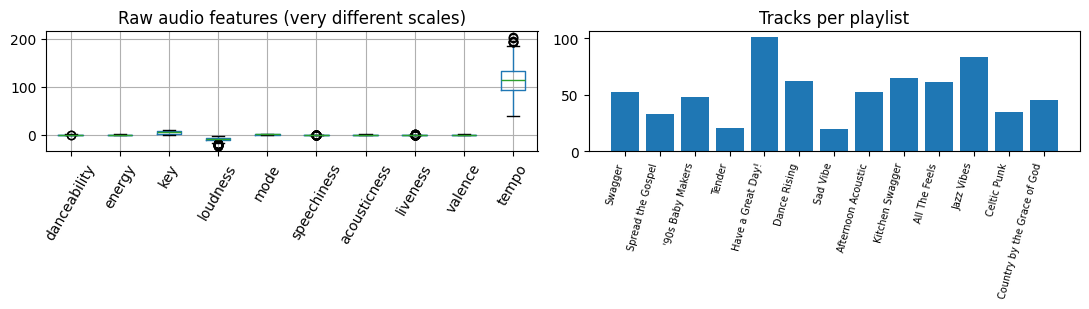

In [18]:
C = len(classes)
print(f"DATA_SOURCE = {DATA_SOURCE} | tracks = {len(X_all)} | classes = {C} | features = {X_all.shape[1]} "
      f"(10 audio + {len(TAG_NAMES)} tags: {TAG_DESC})")
print("tracks with >=1 tag:", int((X_all[:, 10:].sum(1) > 0).sum()))
summary = toy.groupby("playlist").size().reindex(classes).rename("ours").to_frame()
summary["paper Table 2 support"] = pd.Series(PAPER_SUPPORT)
if DATA_SOURCE == "paper" and "feat_source" in toy:
    summary = summary.join(toy.groupby(["playlist", "feat_source"]).size().unstack(fill_value=0))
display(summary.T)

# Fixed 80/20 stratified split used by EVERY model (fair comparison)
idx = np.arange(len(X_all))
tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
X_tr, X_te, y_tr, y_te = X_all[tr_idx], X_all[te_idx], y_all[tr_idx], y_all[te_idx]
print("train", X_tr.shape, "test", X_te.shape)
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
pd.DataFrame(X_all[:, :10], columns=AUDIO).boxplot(ax=ax[0], rot=60); ax[0].set_title("Raw audio features (very different scales)")
ax[1].bar(range(C), np.bincount(y_all, minlength=C)); ax[1].set_xticks(range(C))
ax[1].set_xticklabels(classes, rotation=75, ha="right", fontsize=7); ax[1].set_title("Tracks per playlist")
plt.tight_layout(); plt.show()

# PART 1 — Reproduce the reported results

## 3. Perceptron and SVMs: scaled vs. unscaled (paper Table 1)
Paper: Perceptron + Polynomial / Sigmoid / RBF SVMs, with and without standardisation (subtract mean, divide by std), **5-fold CV**, test accuracy as mean ± std. scikit-learn defaults are used because the paper doesn't state kernel hyper-parameters (`C=1`, `gamma='scale'`, polynomial `degree=3`). Scaling is inside a `Pipeline`, so it is fit only on each training fold (no leakage).

In [19]:
REPORTED_T1 = {   # (scaled mean, scaled std, unscaled mean, unscaled std) - paper Table 1
    "RBF SVM":     (0.77, 0.05, 0.25, 0.04),
    "Sigmoid SVM": (0.74, 0.07, 0.09, 0.04),
    "Poly SVM":    (0.17, 0.02, 0.48, 0.05),
    "Perceptron":  (0.76, 0.05, 0.13, 0.10),
}
make = {
    "RBF SVM":     lambda: SVC(kernel="rbf"),
    "Sigmoid SVM": lambda: SVC(kernel="sigmoid"),
    "Poly SVM":    lambda: SVC(kernel="poly"),
    "Perceptron":  lambda: Perceptron(max_iter=1000, tol=1e-3, random_state=SEED),
}
t1 = {}   # name -> dict(scaled=(m,s), unscaled=(m,s), holdout_scaled, holdout_unscaled)
for name, mk in make.items():
    t1[name] = {}
    for tag, scaled in [("scaled", True), ("unscaled", False)]:
        est = make_pipeline(StandardScaler(), mk()) if scaled else mk()
        sc = cross_val_score(est, X_all, y_all, cv=skf, n_jobs=-1)
        ho = accuracy_score(y_te, est.fit(X_tr, y_tr).predict(X_te))
        t1[name][tag] = (sc.mean(), sc.std()); t1[name][tag + "_holdout"] = ho

rows = []
for name in make:
    rs, ru = REPORTED_T1[name][:2], REPORTED_T1[name][2:]
    rows.append({"Model": name,
        "Scaled: reported": f"{rs[0]:.2f} ± {rs[1]:.2f}",
        "Scaled: yours (5-fold CV)": f"{t1[name]['scaled'][0]:.2f} ± {t1[name]['scaled'][1]:.2f}",
        "Unscaled: reported": f"{ru[0]:.2f} ± {ru[1]:.2f}",
        "Unscaled: yours (5-fold CV)": f"{t1[name]['unscaled'][0]:.2f} ± {t1[name]['unscaled'][1]:.2f}",
        "Yours: hold-out 20% (scaled)": f"{t1[name]['scaled_holdout']:.2f}"})
table1 = pd.DataFrame(rows).set_index("Model")
table1

,Scaled: reported,Scaled: yours (5-fold CV),Unscaled: reported,Unscaled: yours (5-fold CV),Yours: hold-out 20% (scaled)
Model,,,,,
RBF SVM,0.77 ± 0.05,0.70 ± 0.04,0.25 ± 0.04,0.20 ± 0.01,0.71
Sigmoid SVM,0.74 ± 0.07,0.75 ± 0.03,0.09 ± 0.04,0.18 ± 0.02,0.73
Poly SVM,0.17 ± 0.02,0.29 ± 0.03,0.48 ± 0.05,0.15 ± 0.01,0.25
Perceptron,0.76 ± 0.05,0.76 ± 0.02,0.13 ± 0.10,0.16 ± 0.05,0.70


## 4. Tuned RBF SVM and per-class report (paper Table 2)
Paper: tune the penalty parameter on the error term (`C`) of the RBF SVM → **0.80 ± 0.05** test accuracy, then report precision / recall / F1 per playlist. We tune `C` and `gamma` by 5-fold CV **on the training split only**, then report accuracy on the held-out 20%, and the 5-fold CV mean ± std of the tuned model (the way the paper reports its figure).

In [20]:
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grid = {"svc__C": [0.1, 1, 10, 100, 1000], "svc__gamma": ["scale", 1e-4, 3e-4, 1e-3, 3e-3]}
gs = GridSearchCV(pipe, grid, cv=skf, n_jobs=-1).fit(X_tr, y_tr)
best_svm = gs.best_estimator_
svm_pred = best_svm.predict(X_te)
svm_test_acc = accuracy_score(y_te, svm_pred)
cv_best = cross_val_score(make_pipeline(StandardScaler(),
          SVC(kernel="rbf", C=gs.best_params_["svc__C"], gamma=gs.best_params_["svc__gamma"])),
          X_all, y_all, cv=skf, n_jobs=-1)
print("best params:", gs.best_params_)
print(f"tuned RBF SVM  | hold-out test acc = {svm_test_acc:.3f} | 5-fold CV = {cv_best.mean():.2f} ± {cv_best.std():.2f}   (paper: 0.80 ± 0.05)")

PAPER_PRF = {  # paper Table 2: precision, recall, F1
 "Swagger":(0.65,0.62,0.64),"Spread the Gospel":(1.00,0.93,0.96),"'90s Baby Makers":(0.74,0.79,0.76),
 "Tender":(0.75,0.36,0.49),"Have a Great Day!":(0.69,0.83,0.75),"Dance Rising":(0.85,0.94,0.89),
 "Sad Vibe":(0.71,0.83,0.77),"Afternoon Acoustic":(0.79,0.80,0.80),"Kitchen Swagger":(0.49,0.43,0.46),
 "All The Feels":(0.85,0.88,0.86),"Jazz Vibes":(0.92,0.92,0.92),"Celtic Punk":(1.00,0.94,0.97),
 "Country by the Grace of God":(0.95,0.84,0.89)}

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(C), zero_division=0)
    return pd.DataFrame({"Precision": p, "Recall": r, "F1": f, "Support(test)": s}, index=classes)

pc_svm = per_class_table(y_te, svm_pred)
tab2 = pc_svm.copy()
tab2["Paper P"] = [PAPER_PRF[c][0] for c in classes]
tab2["Paper R"] = [PAPER_PRF[c][1] for c in classes]
tab2["Paper F1"] = [PAPER_PRF[c][2] for c in classes]
tab2.round(2)

best params: {'svc__C': 100, 'svc__gamma': 0.0001}
tuned RBF SVM  | hold-out test acc = 0.699 | 5-fold CV = 0.74 ± 0.04   (paper: 0.80 ± 0.05)


,Precision,Recall,F1,Support(test),Paper P,Paper R,Paper F1
Swagger,0.53,0.90,0.67,10,0.65,0.62,0.64
Spread the Gospel,1.00,0.86,0.92,7,1.00,0.93,0.96
'90s Baby Makers,0.83,1.00,0.91,10,0.74,0.79,0.76
Tender,0.00,0.00,0.00,4,0.75,0.36,0.49
Have a Great Day!,0.86,0.60,0.71,20,0.69,0.83,0.75
Dance Rising,1.00,0.54,0.70,13,0.85,0.94,0.89
Sad Vibe,0.00,0.00,0.00,4,0.71,0.83,0.77
Afternoon Acoustic,0.89,0.80,0.84,10,0.79,0.80,0.80
Kitchen Swagger,0.43,0.46,0.44,13,0.49,0.43,0.46
All The Feels,0.70,0.58,0.64,12,0.85,0.88,0.86


## 5. Neural networks in PyTorch (paper Section 5.2, Fig. 2, Table 3)
Paper setup: input → hidden layer(s) → `LogSoftmax`, **NLL loss**, **full-batch gradient descent**, **L2 regularisation**, 150 epochs, standardised inputs. Two architectures:

* **1 hidden layer**: `C` neurons, sigmoid (paper: 0.89 train / 0.82 test)
* **2 hidden layers**: `2C` (identity) then `C` (sigmoid) neurons (paper: 0.91 train / 0.77 test)

Learning rate and L2 strength are not given, so we pick them on a **validation split of the training data** (never on the test set). The search grid excludes zero weight decay, so the L2 term the paper describes is always active. Because NN results depend on the random initialisation, the table reports mean ± std over several seeds.

1 hidden (sigmoid)               lr=1.0   wd=0.001  val=0.829 | train 0.949±0.001 | test 0.750±0.016
2 hidden (identity + sigmoid)    lr=1.0   wd=0.001  val=0.793 | train 0.957±0.006 | test 0.732±0.014


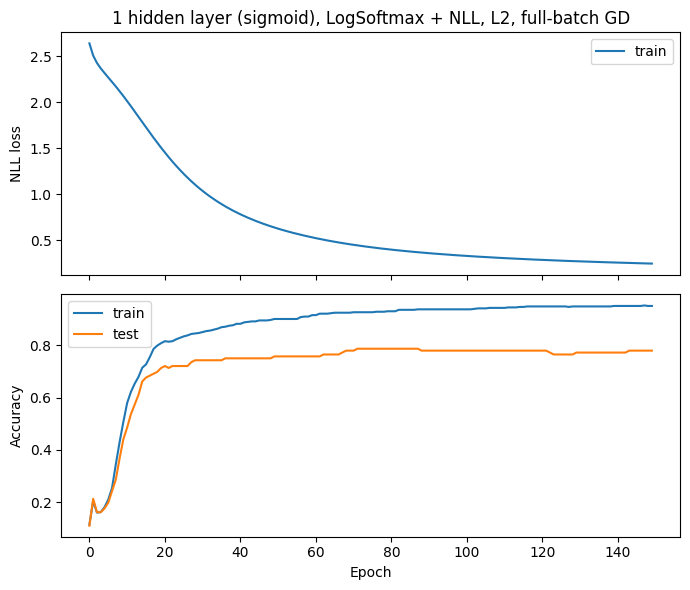

In [21]:
ACTS = {"sigmoid": nn.Sigmoid, "identity": nn.Identity}

def make_mlp(d_in, hidden, acts, d_out):
    layers, prev = [], d_in
    for h, a in zip(hidden, acts):
        layers += [nn.Linear(prev, h), ACTS[a]()]; prev = h
    layers += [nn.Linear(prev, d_out), nn.LogSoftmax(dim=1)]
    return nn.Sequential(*layers)

def train_nn(Xtr, ytr, Xev, yev, hidden, acts, lr, wd, epochs=NN_EPOCHS, seed=0):
    # Full-batch GD, NLL loss, L2 via weight_decay. Inputs must already be scaled.
    torch.manual_seed(seed)
    Xt, yt = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.long)
    Xe, ye = torch.tensor(Xev, dtype=torch.float32), torch.tensor(yev, dtype=torch.long)
    model = make_mlp(Xt.shape[1], hidden, acts, int(max(ytr.max(), yev.max())) + 1)
    opt = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.NLLLoss()
    hist = {"loss": [], "train_acc": [], "eval_acc": []}
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        out = model(Xt); loss = lossf(out, yt); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            hist["loss"].append(loss.item())
            hist["train_acc"].append((model(Xt).argmax(1) == yt).float().mean().item())
            hist["eval_acc"].append((model(Xe).argmax(1) == ye).float().mean().item())
    return model, hist

def predict_nn(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32)).argmax(1).numpy()

# weight decay (L2) is always on, as in the paper; wd=0 is deliberately excluded from the search
NN_GRID = [(lr, wd) for lr in (0.05, 0.2, 1.0, 3.0) for wd in (1e-3, 3e-3, 1e-2, 3e-2)]

def select_nn_hparams(X, y, hidden, acts, grid=NN_GRID):
    # Pick (lr, weight_decay) on a validation split carved out of the TRAIN data only.
    a, b = train_test_split(np.arange(len(X)), test_size=0.15, stratify=y, random_state=SEED)
    sc = StandardScaler().fit(X[a]); Xa, Xb = sc.transform(X[a]), sc.transform(X[b])
    best, best_acc = None, -1
    for lr, wd in grid:
        _, h = train_nn(Xa, y[a], Xb, y[b], hidden, acts, lr, wd)
        acc = np.mean(h["eval_acc"][-5:])
        if acc > best_acc: best, best_acc = (lr, wd), acc
    return best, best_acc

scaler_nn = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = scaler_nn.transform(X_tr), scaler_nn.transform(X_te)

ARCHS = {"1 hidden (sigmoid)":            ([C],        ["sigmoid"]),
         "2 hidden (identity + sigmoid)": ([2 * C, C], ["identity", "sigmoid"])}
nn_res = {}
for name, (hid, act) in ARCHS.items():
    (lr, wd), vacc = select_nn_hparams(X_tr, y_tr, hid, act)
    runs, hists, models = [], [], []
    for s in range(NN_SEEDS):
        m, h = train_nn(Xs_tr, y_tr, Xs_te, y_te, hid, act, lr, wd, seed=s)
        runs.append((h["train_acc"][-1], h["eval_acc"][-1])); hists.append(h); models.append(m)
    runs = np.array(runs)
    nn_res[name] = dict(lr=lr, wd=wd, val_acc=vacc, train=runs[:, 0], test=runs[:, 1],
                        hist=hists[0], model=models[0])
    print(f"{name:32s} lr={lr:<5} wd={wd:<6} val={vacc:.3f} | train {runs[:,0].mean():.3f}±{runs[:,0].std():.3f}"
          f" | test {runs[:,1].mean():.3f}±{runs[:,1].std():.3f}")

# Fig. 2 analogue: loss and accuracy curves (seed 0, 1-hidden-layer network)
h = nn_res["1 hidden (sigmoid)"]["hist"]
fig, ax = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax[0].plot(h["loss"], label="train"); ax[0].set_ylabel("NLL loss"); ax[0].legend()
ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["eval_acc"], label="test")
ax[1].set_ylabel("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
ax[0].set_title("1 hidden layer (sigmoid), LogSoftmax + NLL, L2, full-batch GD")
plt.tight_layout(); plt.show()

## 6. (Proxy) user-level experiments — paper Table 4, Fig. 3, segmentation
The paper's Table 4 uses friends' **private** playlists, so it cannot be reproduced. As a transparent proxy we create two synthetic "users" from the public dataset and use **audio features only** (artist tags would make genre-defined playlists trivially separable):

* a **separable user** (playlists from very different genres), like Jacob;
* an **overlapping user** (playlists from similar-sounding metal/rock sub-genres), like Myles.

This shows the same *qualitative* effect (overlapping playlists are much harder) and the paper's **segmentation** idea (classify among ≤5 playlists at a time). It is *not* a numerical reproduction of Table 4.

,#playlists,NN train,NN test,RBF-SVM train,RBF-SVM test
User (proxy),,,,,
Separable user (Jacob-like),7,0.64,0.63,0.76,0.71
Overlapping user (Myles-like),8,0.40,0.22,0.58,0.33


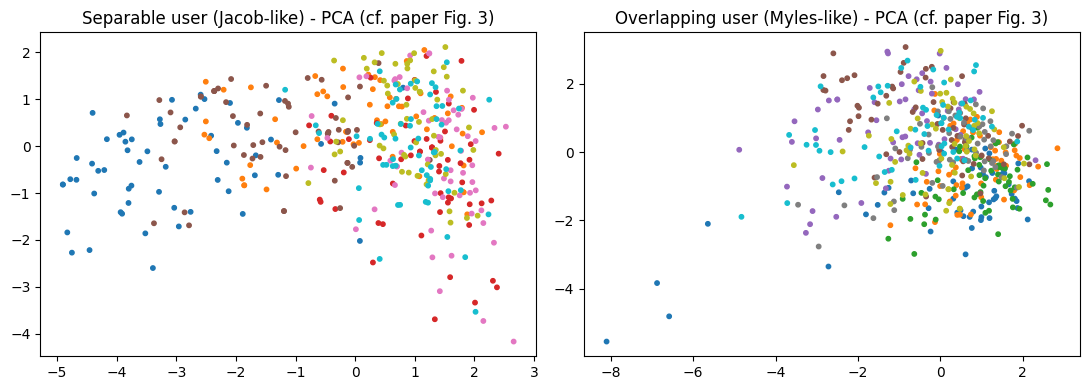

Segmentation (5 of 8 playlists, RBF SVM, 100 trials): 0.46 ± 0.06  vs all 8 playlists at once: 0.33


In [22]:
def make_user(genres, per_playlist=60, seed=SEED):
    g = [x for x in genres if x in avail]
    if len(g) < 3: return None, None, g
    d = raw[raw.track_genre.isin(g)]
    d = d[~d.track_id.isin(d.track_id[d.track_id.duplicated(keep=False)])].drop_duplicates("track_id")
    d = pd.concat([x.sample(min(len(x), per_playlist), random_state=seed) for _, x in d.groupby("track_genre")])
    codes = {x: i for i, x in enumerate(sorted(g))}
    return d[AUDIO].to_numpy(np.float32), d.track_genre.map(codes).to_numpy(), sorted(g)

USERS = {
 "Separable user (Jacob-like)":  ["classical", "techno", "country", "jazz", "hip-hop", "reggae", "salsa"],
 "Overlapping user (Myles-like)": ["metal", "heavy-metal", "death-metal", "black-metal", "hard-rock",
                                   "grindcore", "hardcore", "punk-rock"],
}
nn_lr, nn_wd = nn_res["1 hidden (sigmoid)"]["lr"], nn_res["1 hidden (sigmoid)"]["wd"]
user_rows, user_pca = [], {}
if RUN_PROXY_USERS and raw is None:
    print("Skipping Section 6: it needs the public Spotify Tracks Dataset (set DATA_PATH or enable internet access).")
if RUN_PROXY_USERS and raw is not None:
    for uname, gl in USERS.items():
        Xu, yu, used = make_user(gl)
        if Xu is None:
            print("skipping", uname, "- genres not available"); continue
        a, b = train_test_split(np.arange(len(Xu)), test_size=0.2, stratify=yu, random_state=SEED)
        sc = StandardScaler().fit(Xu[a]); Xa, Xb = sc.transform(Xu[a]), sc.transform(Xu[b])
        k = len(used)
        m, hh = train_nn(Xa, yu[a], Xb, yu[b], [k], ["sigmoid"], nn_lr, nn_wd)
        svm_u = SVC(kernel="rbf").fit(Xa, yu[a])
        user_rows.append({"User (proxy)": uname, "#playlists": k,
            "NN train": hh["train_acc"][-1], "NN test": hh["eval_acc"][-1],
            "RBF-SVM train": svm_u.score(Xa, yu[a]), "RBF-SVM test": svm_u.score(Xb, yu[b])})
        user_pca[uname] = (PCA(2).fit_transform(sc.transform(Xu)), yu)
    users_table = pd.DataFrame(user_rows).set_index("User (proxy)").round(2)
    display(users_table)

    fig, ax = plt.subplots(1, len(user_pca), figsize=(11, 4))
    ax = np.atleast_1d(ax)
    for a_, (u, (Z, yy)) in zip(ax, user_pca.items()):
        a_.scatter(Z[:, 0], Z[:, 1], c=yy, cmap="tab10", s=10); a_.set_title(u + " - PCA (cf. paper Fig. 3)")
    plt.tight_layout(); plt.show()

    # segmentation: classify among a random subset of <=5 playlists at a time (paper: 100 trials)
    Xo, yo, used_o = make_user(USERS["Overlapping user (Myles-like)"])
    if Xo is not None and len(used_o) > 5:
        rs, accs = np.random.RandomState(SEED), []
        for _ in range(100):
            sub = rs.choice(len(used_o), 5, replace=False)
            mask = np.isin(yo, sub)
            Xs_, ys_ = Xo[mask], yo[mask]
            a, b = train_test_split(np.arange(len(Xs_)), test_size=0.2, stratify=ys_, random_state=int(rs.randint(1e6)))
            sc = StandardScaler().fit(Xs_[a])
            accs.append(SVC(kernel="rbf").fit(sc.transform(Xs_[a]), ys_[a]).score(sc.transform(Xs_[b]), ys_[b]))
        full = users_table.loc["Overlapping user (Myles-like)", "RBF-SVM test"] if "Overlapping user (Myles-like)" in users_table.index else float("nan")
        print(f"Segmentation (5 of {len(used_o)} playlists, RBF SVM, 100 trials): "
              f"{np.mean(accs):.2f} ± {np.std(accs):.2f}  vs all {len(used_o)} playlists at once: {full:.2f}")

## 7. Reported vs. Your Result (required comparison table)
The paper's own CV standard deviation is ≈ ±0.05, so a difference up to ~5 percentage points counts as *close*; larger differences are explained in Section 10.

In [23]:
def row(exp, metric, rep, yours):
    return {"Experiment": exp, "Metric": metric, "Reported": rep, "Yours": round(float(yours), 3),
            "Δ (pp)": round((float(yours) - rep) * 100, 1),
            "Close (|Δ|≤5pp)": "yes" if abs(float(yours) - rep) <= 0.05 else "no"}
R = []
for name in make:
    R.append(row(f"{name} (scaled, 5-fold CV)",   "test acc", REPORTED_T1[name][0], t1[name]["scaled"][0]))
    R.append(row(f"{name} (unscaled, 5-fold CV)", "test acc", REPORTED_T1[name][2], t1[name]["unscaled"][0]))
R.append(row("Tuned RBF SVM (5-fold CV)", "test acc", 0.80, cv_best.mean()))
n1, n2 = nn_res["1 hidden (sigmoid)"], nn_res["2 hidden (identity + sigmoid)"]
R += [row("NN 1 hidden (sigmoid)", "train acc", 0.89, n1["train"].mean()),
      row("NN 1 hidden (sigmoid)", "test acc",  0.82, n1["test"].mean()),
      row("NN 2 hidden (identity+sigmoid)", "train acc", 0.91, n2["train"].mean()),
      row("NN 2 hidden (identity+sigmoid)", "test acc",  0.77, n2["test"].mean())]
reported_vs_yours = pd.DataFrame(R)
display(reported_vs_yours)

# paper's qualitative claims, checked on our data
claims = {
 "Scaling helps RBF SVM (scaled > unscaled)":            t1["RBF SVM"]["scaled"][0] > t1["RBF SVM"]["unscaled"][0],
 "Scaling helps Sigmoid SVM":                            t1["Sigmoid SVM"]["scaled"][0] > t1["Sigmoid SVM"]["unscaled"][0],
 "Scaling helps Perceptron":                             t1["Perceptron"]["scaled"][0] > t1["Perceptron"]["unscaled"][0],
 "Tuned RBF SVM beats default RBF SVM":                  cv_best.mean() > t1["RBF SVM"]["scaled"][0],
 "1-hidden-layer NN >= tuned RBF SVM (test)":            n1["test"].mean() >= svm_test_acc,
 "1-hidden-layer NN > 2-hidden-layer NN (test)":         n1["test"].mean() > n2["test"].mean(),
}
pd.Series(claims, name="holds on our data?").to_frame()

,Experiment,Metric,Reported,Yours,Δ (pp),Close (|Δ|≤5pp)
0,"RBF SVM (scaled, 5-fold CV)",test acc,0.77,0.696,-7.4,no
1,"RBF SVM (unscaled, 5-fold CV)",test acc,0.25,0.201,-4.9,yes
2,"Sigmoid SVM (scaled, 5-fold CV)",test acc,0.74,0.752,1.2,yes
3,"Sigmoid SVM (unscaled, 5-fold CV)",test acc,0.09,0.184,9.4,no
4,"Poly SVM (scaled, 5-fold CV)",test acc,0.17,0.291,12.1,no
5,"Poly SVM (unscaled, 5-fold CV)",test acc,0.48,0.148,-33.2,no
6,"Perceptron (scaled, 5-fold CV)",test acc,0.76,0.760,-0.0,yes
7,"Perceptron (unscaled, 5-fold CV)",test acc,0.13,0.156,2.6,yes
8,Tuned RBF SVM (5-fold CV),test acc,0.80,0.745,-5.5,no
9,NN 1 hidden (sigmoid),train acc,0.89,0.949,5.9,no


,holds on our data?
Scaling helps RBF SVM (scaled > unscaled),True
Scaling helps Sigmoid SVM,True
Scaling helps Perceptron,True
Tuned RBF SVM beats default RBF SVM,True
1-hidden-layer NN >= tuned RBF SVM (test),True
1-hidden-layer NN > 2-hidden-layer NN (test),True
